In [1]:

import re
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")


TensorFlow version: 2.21.0
Libraries imported successfully!


In [4]:

import pandas as pd

fake = pd.read_csv(
    "/content/Fake.csv",
    engine="python",
    on_bad_lines="skip"
)

real = pd.read_csv(
    "/content/True.csv",
    engine="python",
    on_bad_lines="skip"
)

print("Fake dataset shape:", fake.shape)
print("Real dataset shape:", real.shape)

print("\nFake dataset columns:", fake.columns.tolist())
print("Real dataset columns:", real.columns.tolist())

print("\nFiles loaded successfully!")


Fake dataset shape: (23481, 4)
Real dataset shape: (21417, 4)

Fake dataset columns: ['title', 'text', 'subject', 'date']
Real dataset columns: ['title', 'text', 'subject', 'date']

Files loaded successfully!


In [5]:

import pandas as pd

# Assign labels: 0 = Fake, 1 = Real
fake["label"] = 0
real["label"] = 1

# Combine both datasets
df = pd.concat([fake, real], ignore_index=True)

# Handle missing values
df["title"] = df["title"].fillna("")
df["text"] = df["text"].fillna("")

# Combine title and article text
df["news"] = df["title"] + " " + df["text"]

# Remove empty articles and duplicates
df["news"] = df["news"].str.strip()
df = df[df["news"] != ""]
df = df.drop_duplicates(subset="news")

# Select a balanced subset of 2000 articles
fake_df = df[df["label"] == 0].sample(n=1000, random_state=42)
real_df = df[df["label"] == 1].sample(n=1000, random_state=42)

df = pd.concat([fake_df, real_df], ignore_index=True)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Final dataset shape:", df.shape)
print("\nLabel distribution:")
print(df["label"].value_counts())
print("\nSample articles:")
display(df[["news", "label"]].head())


Final dataset shape: (2000, 6)

Label distribution:
label
1    1000
0    1000
Name: count, dtype: int64

Sample articles:


,news,label
0,"In Georgia, costliest U.S. House race hits ugl...",1
1,"Bernie Gives Us Hope, Promises To Protect Mino...",0
2,U.S. appeals court questions scope of Trump tr...,1
3,Trump ‘Promises’ To Fix Black People’s Problem...,0
4,Countdown to Brexit breakthrough? BRUSSELS (Re...,1


In [6]:

import re
import html

def clean_text(text):
    text = html.unescape(str(text))
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["news"] = df["news"].apply(clean_text)

X = df["news"].values
y = df["label"].values

print("Text preprocessing completed!")
print("\nCleaned example:")
print(X[0])


Text preprocessing completed!

Cleaned example:
in georgia, costliest u.s. house race hits ugly note as election looms atlanta (reuters) - the costliest u.s. congressional race in history will be decided on tuesday in suburban atlanta, where america’s divisive political climate has been on display in an election seen by some analysts as a political test for president donald trump. days after a lone gunman opened fire on u.s. lawmakers at a baseball team practice in virginia, a conservative group was running a tv ad in atlanta that, with no evidence, appears to link the democratic candidate, jon ossoff, to the shooting spree. ossoff called the ad “shameful” in a statement. the atlanta journal-constitution newspaper reported that ossoff’s republican opponent, karen handel, also condemned the ad. it was an ugly, last-minute twist in the ossoff-handel contest for the u.s. house of representatives seat vacated by tom price, who resigned after becoming trump’s secretary of the health and hum

In [7]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 1600
Testing samples: 400


In [8]:

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

VOCAB_SIZE = 10000
MAX_LENGTH = 200

tokenizer = Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token="<OOV>"
)

# Learn vocabulary only from training articles
tokenizer.fit_on_texts(X_train)

train_sequences = tokenizer.texts_to_sequences(X_train)
test_sequences = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    train_sequences,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    test_sequences,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)
print("Tokenization and padding completed!")


Training shape: (1600, 200)
Testing shape: (400, 200)
Tokenization and padding completed!


In [9]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)

model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=32,
        mask_zero=True
    ),
    LSTM(32),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=1,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    validation_split=0.1,
    epochs=4,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

print("LSTM training completed!")


Epoch 1/4
45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 88ms/step - accuracy: 0.5944 - loss: 0.6752 - val_accuracy: 0.9062 - val_loss: 0.4927
Epoch 2/4
45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - accuracy: 0.8757 - loss: 0.4091 - val_accuracy: 0.8000 - val_loss: 0.5127
LSTM training completed!


In [10]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict probabilities on the test set
y_prob = model.predict(X_test_pad, verbose=0).ravel()

# Convert probabilities into labels
# 0 = Fake News, 1 = Real News
y_pred = (y_prob >= 0.5).astype(int)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("LSTM TEST RESULTS")
print("-----------------------")
print(f"Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Fake News", "Real News"],
    zero_division=0
))


LSTM TEST RESULTS
-----------------------
Accuracy : 0.9125 (91.25%)
Precision: 0.8733
Recall   : 0.9650
F1-score : 0.9169

Detailed classification report:
              precision    recall  f1-score   support

   Fake News       0.96      0.86      0.91       200
   Real News       0.87      0.96      0.92       200

    accuracy                           0.91       400
   macro avg       0.92      0.91      0.91       400
weighted avg       0.92      0.91      0.91       400



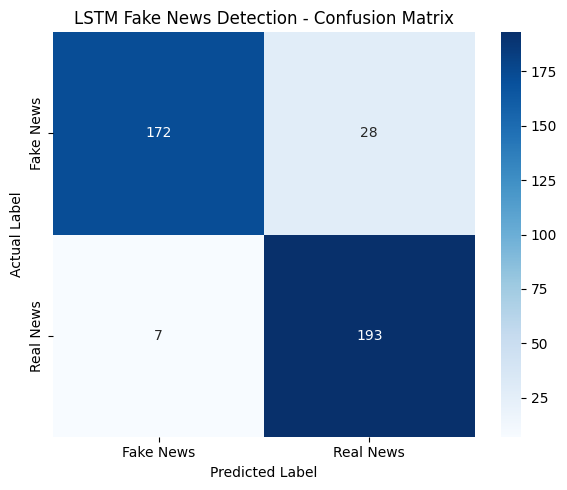

Confusion matrix:
[[172  28]
 [  7 193]]


In [11]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake News", "Real News"],
    yticklabels=["Fake News", "Real News"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("LSTM Fake News Detection - Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)


In [12]:

def predict_news(article):
    cleaned = clean_text(article)

    sequence = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(
        sequence,
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post"
    )

    prob_real = float(model.predict(padded, verbose=0)[0][0])

    prediction = "Real News" if prob_real >= 0.5 else "Fake News"

    print("Article:", article)
    print("Predicted class:", prediction)
    print(f"Real News score: {prob_real:.4f}")
    print(f"Fake News score: {1 - prob_real:.4f}")
    print("-" * 60)

predict_news(
    "The central bank announced its latest monetary policy "
    "decision following a scheduled meeting."
)

predict_news(
    "A secret miracle treatment cures every disease instantly, "
    "but authorities are hiding the discovery from everyone."
)


Article: The central bank announced its latest monetary policy decision following a scheduled meeting.
Predicted class: Real News
Real News score: 0.5340
Fake News score: 0.4660
------------------------------------------------------------
Article: A secret miracle treatment cures every disease instantly, but authorities are hiding the discovery from everyone.
Predicted class: Fake News
Real News score: 0.4878
Fake News score: 0.5122
------------------------------------------------------------


Accuracy : 0.9125
Precision: 0.8733
Recall   : 0.965
F1-score : 0.9169


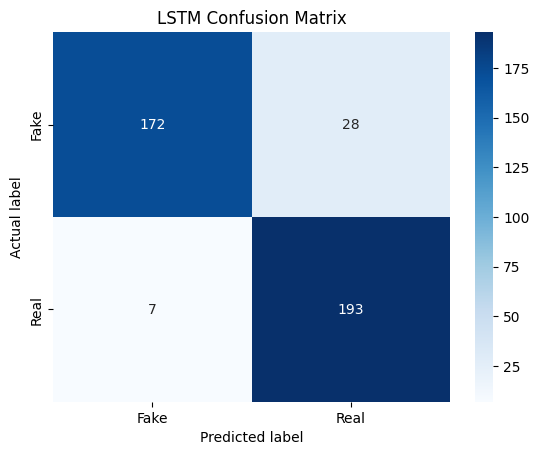

In [13]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

y_prob = model.predict(X_test_pad, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0), 4))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("LSTM Confusion Matrix")
plt.show()
